# Diabetes 130-US Hospitals: 30-day readmission prediction

**Goal:** predict whether a diabetic inpatient will be readmitted **within 30 days** of discharge.

This notebook covers:
1. Data preparation and cleaning
2. Exploratory data analysis (EDA) and feature importance
3. Model selection and hyper-parameter tuning (see the second half)

Data: UCI *Diabetes 130-US hospitals for years 1999-2008* (101,766 encounters, 50 columns).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from features import load_data, prepare_features, icd9_group, MED_COLS, NUM_COLS, CAT_COLS

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

raw = pd.read_csv("data/diabetic_data.csv", na_values="?", keep_default_na=False)
print(raw.shape)
raw.head()

(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 1. Data overview

In [2]:
raw.dtypes.value_counts()

object    37
int64     13
Name: count, dtype: int64

In [3]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.024006e+00,1.445403e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.715642e+00,5.280166e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.754437e+00,4.064081e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.395987e+00,2.985108e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.309564e+01,1.967436e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.339730e+00,1.705807e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602184e+01,8.127566e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.693572e-01,1.267265e+00,0.0,0.0,0.0,0.000000e+00,42.0


### Missing values
Missing values are encoded as `?` in the raw file (read as NaN above).

weight               96.86
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64


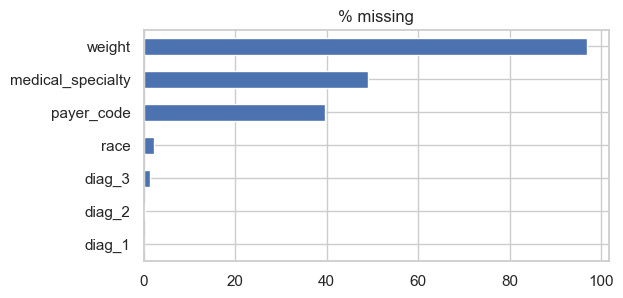

In [4]:
miss = raw.isna().mean().mul(100).sort_values(ascending=False)
miss = miss[miss > 0]
print(miss.round(2))
miss.plot.barh(figsize=(6, 3), title="% missing")
plt.gca().invert_yaxis(); plt.show()

* `weight` is 97% missing -> **drop**.
* `payer_code` (40%) and `medical_specialty` (49%) -> keep, missing becomes an explicit `unknown` category.
* `race`, `diag_1..3` have few missing values -> `unknown` category as well.

### Constant / useless columns

In [5]:
nun = raw.nunique().sort_values()
print(nun.head(8))
print("encounter_id unique:", raw.encounter_id.is_unique, "| patients:", raw.patient_nbr.nunique())

examide                    1
citoglipton                1
troglitazone               2
acetohexamide              2
tolbutamide                2
glipizide-metformin        2
diabetesMed                2
metformin-rosiglitazone    2
dtype: int64
encounter_id unique: True | patients: 71518


`examide` and `citoglipton` have a single value -> no information. `encounter_id` is only an identifier.
`patient_nbr` is used only for **grouping** the train/validation/test split, because about 25% of patients appear more than once (together ~46% of all encounters) (otherwise the same patient could leak across splits).

## 2. Target variable

readmitted
NO     0.539
>30    0.349
<30    0.112
Name: proportion, dtype: float64


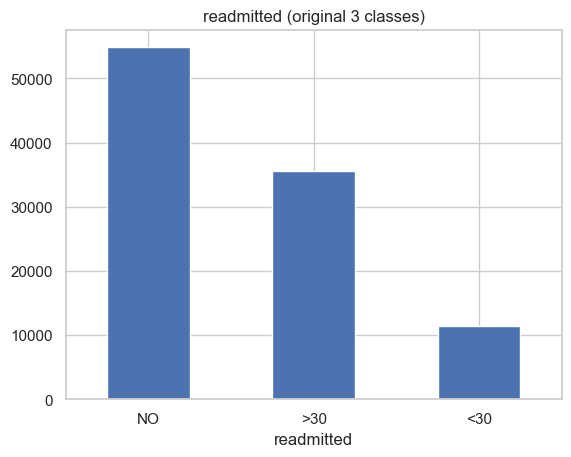

In [6]:
print(raw.readmitted.value_counts(normalize=True).round(3))
raw.readmitted.value_counts().plot.bar(title="readmitted (original 3 classes)", rot=0)
plt.show()

We turn this into a binary problem: `target = 1` if `readmitted == '<30'` (the costly early readmission), otherwise 0.

Encounters whose discharge disposition is *expired* or *hospice* can never be readmitted, so we remove them (they would only add noise).

In [7]:
df = load_data()
print("rows before:", len(raw), "after removing expired/hospice:", len(df))
print("positive rate:", df.target.mean().round(4))

rows before: 101766 after removing expired/hospice: 99343
positive rate: 0.1139


In [8]:
print(df.groupby("patient_nbr").size().value_counts().head(6).rename("encounters per patient"))

1    53649
2    10218
3     3233
4     1354
5      691
6      338
Name: encounters per patient, dtype: int64


## 3. Numeric features

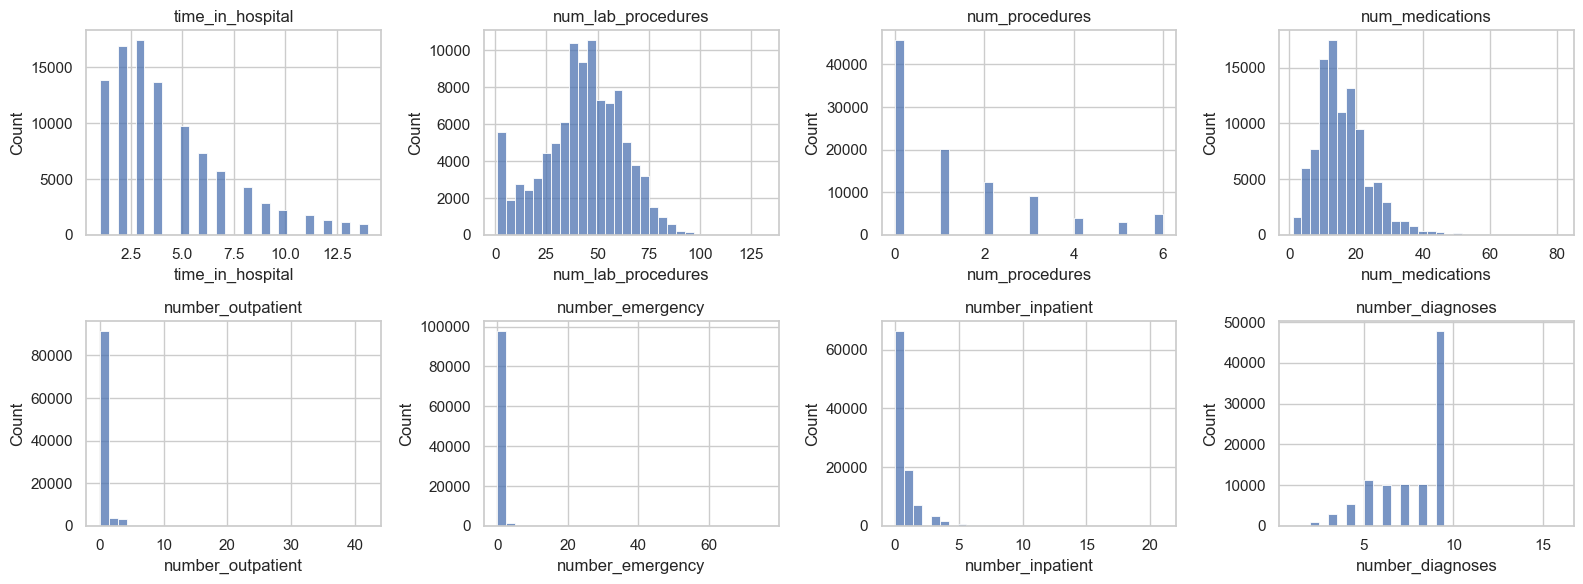

In [9]:
num_raw = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
           "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes.ravel(), num_raw):
    sns.histplot(df[c], bins=30, ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

Counts of prior visits are heavily right-skewed; tree models handle this naturally and for linear models we standardise.

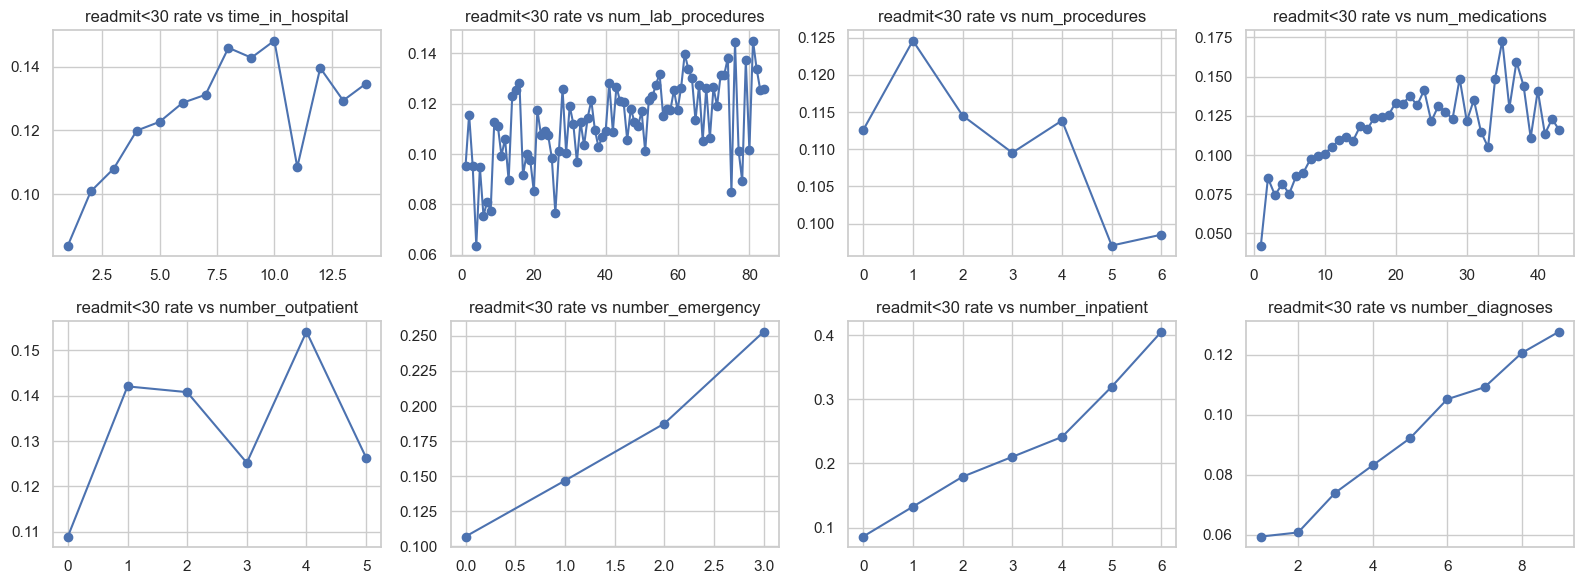

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes.ravel(), num_raw):
    g = df.assign(b=df[c].clip(upper=df[c].quantile(0.99))).groupby("b").target.agg(["mean", "size"])
    g = g[g["size"] >= 100]
    ax.plot(g.index, g["mean"], marker="o"); ax.set_title(f"readmit<30 rate vs {c}")
plt.tight_layout(); plt.show()

**`number_inpatient`** (inpatient visits in the previous year) shows the strongest monotonic relation with early readmission; `number_emergency` and `number_diagnoses` also increase the risk.

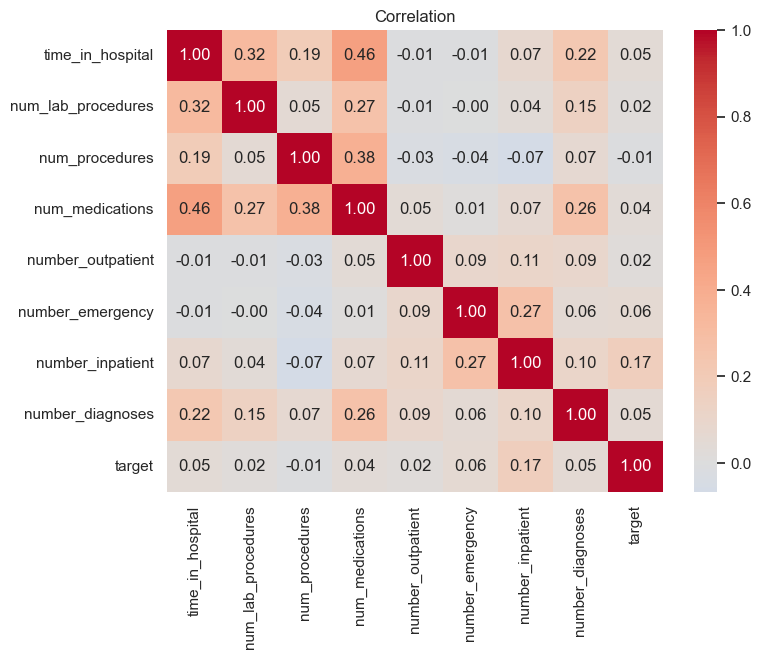

In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_raw + ["target"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation"); plt.show()

## 4. Categorical features

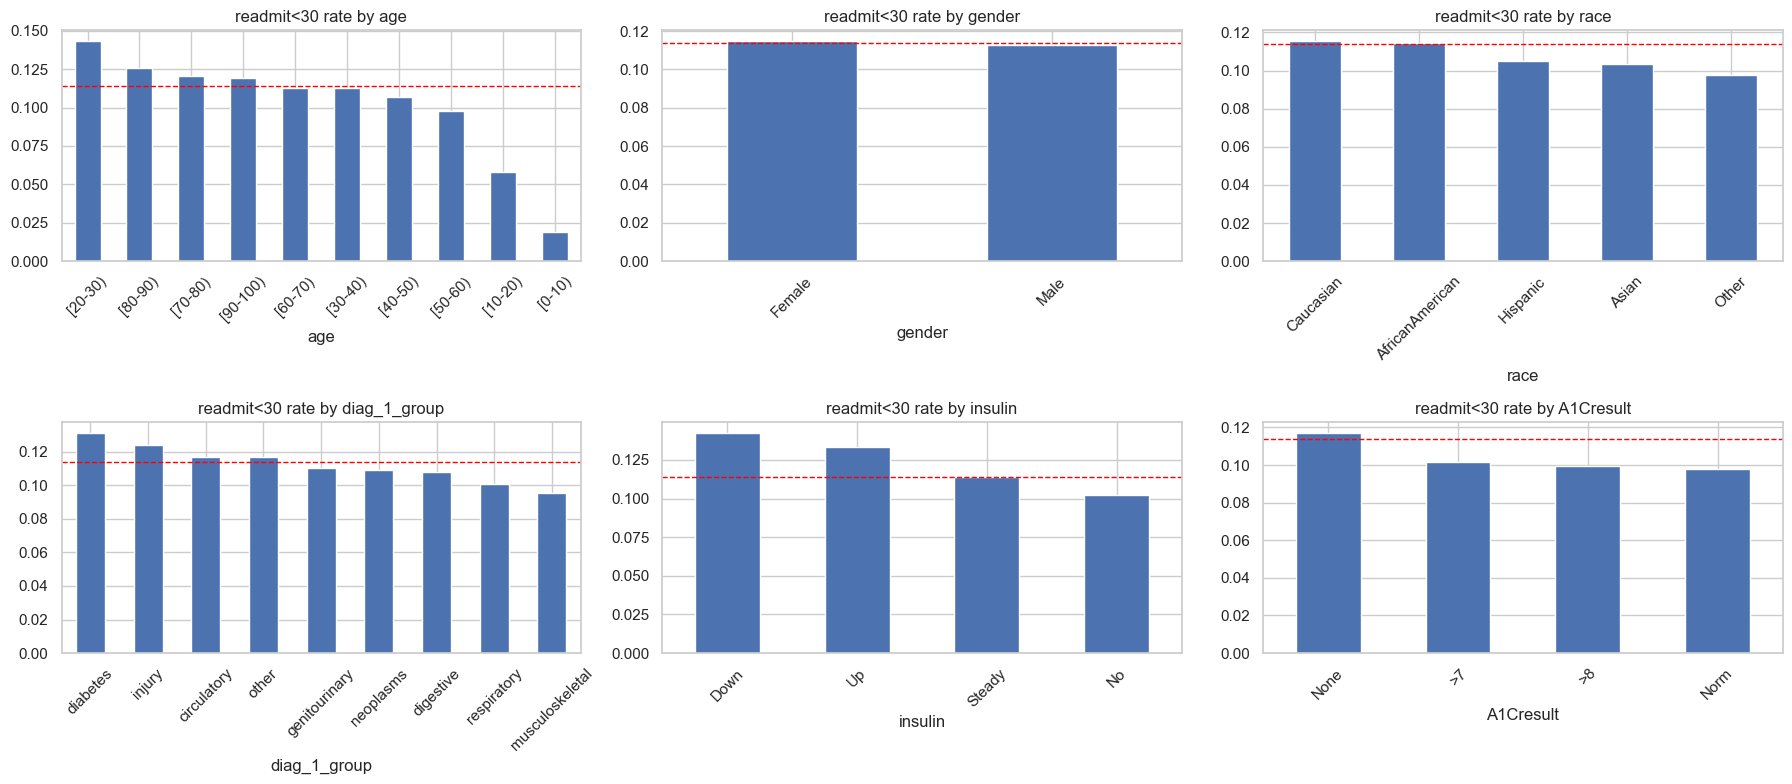

In [12]:
def rate_plot(col, data=df, top=None, ax=None, rot=0):
    g = data.groupby(col).target.agg(["mean", "size"])
    g = g[g["size"] >= 100].sort_values("mean", ascending=False)
    if top: g = g.head(top)
    ax = ax or plt.gca()
    g["mean"].plot.bar(ax=ax, rot=rot)
    ax.axhline(data.target.mean(), color="red", ls="--", lw=1)
    ax.set_title(f"readmit<30 rate by {col}")

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
df["diag_1_group"] = df.diag_1.map(icd9_group)
for ax, c in zip(axes.ravel(), ["age", "gender", "race", "diag_1_group", "insulin", "A1Cresult"]):
    rate_plot(c, ax=ax, rot=45)
plt.tight_layout(); plt.show()

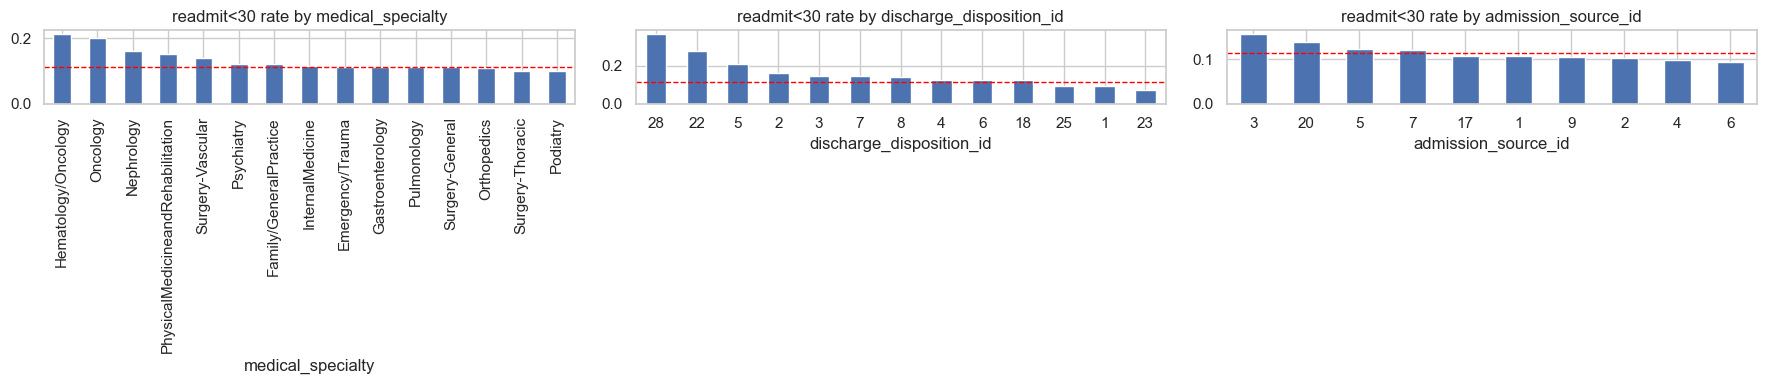

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
rate_plot("medical_specialty", top=15, ax=axes[0], rot=90)
rate_plot("discharge_disposition_id", ax=axes[1])
rate_plot("admission_source_id", ax=axes[2])
plt.tight_layout(); plt.show()

Observations: risk rises with age up to ~[80-90), circulatory/diabetes/respiratory primary diagnoses differ visibly, and discharge destination matters a lot (e.g. transfers to other facilities).
`diag_1..3` have ~700 distinct ICD-9 codes, so we group them into ~9 disease families with `icd9_group()`.

## 5. Patient-history features (feature engineering)

71,518 patients produced 101,766 encounters, so many patients appear several times. For an encounter we can legitimately use what happened in that patient's **earlier** encounters. We build `n_prior_enc`, `prior_lt30_cnt`, `prior_any_cnt`, `prev_lt30`, `prev_any` and `prior_days` in `features.add_patient_history()`, using `encounter_id` as the time order.

Check that `encounter_id` really is chronological: if so, encounters that were followed by an early readmission must usually have a *later* encounter for the same patient.

In [14]:
chk = raw.sort_values(["patient_nbr", "encounter_id"]).copy()
chk["has_later"] = chk.groupby("patient_nbr").cumcount(ascending=False) > 0
print(chk.groupby(chk.readmitted == "<30").has_later.mean().rename("share with a later encounter"))

readmitted
False    0.244611
True     0.716122
Name: share with a later encounter, dtype: float64


72% of the `<30` encounters have a later encounter of the same patient versus 25% for the others, so the ordering is consistent with time. Only *earlier* rows are used for the features, so nothing from the future leaks into a prediction.

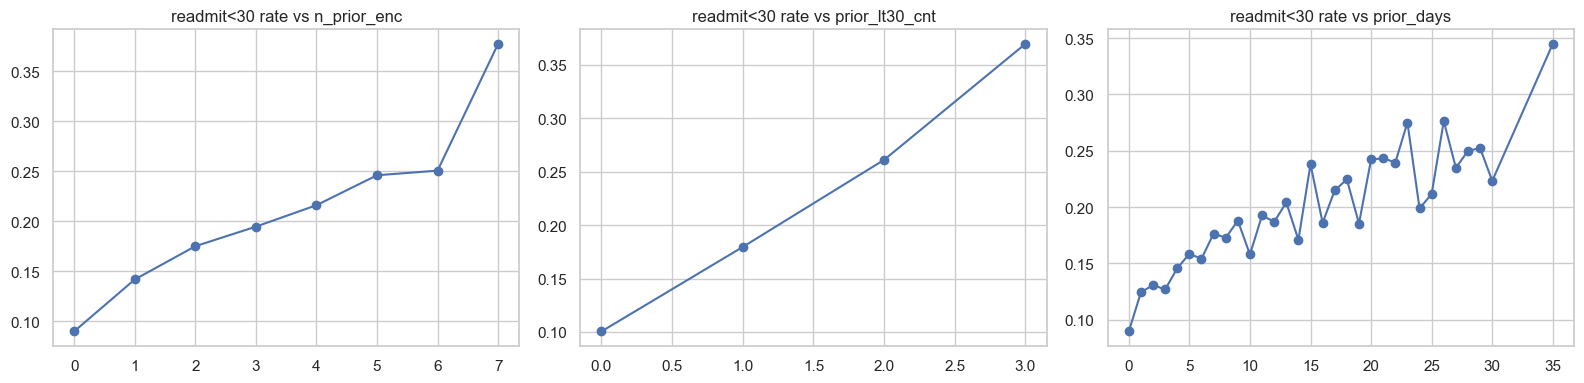

               mean   size
prev_lt30                 
0          0.105169  91500
1          0.215606   7843


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["n_prior_enc", "prior_lt30_cnt", "prior_days"]):
    g_ = df.assign(b=df[c].clip(upper=df[c].quantile(0.99))).groupby("b").target.agg(["mean", "size"])
    g_ = g_[g_["size"] >= 100]
    ax.plot(g_.index, g_["mean"], marker="o"); ax.set_title(f"readmit<30 rate vs {c}")
plt.tight_layout(); plt.show()
print(df.groupby("prev_lt30").target.agg(["mean", "size"]))

Patients with a longer history and especially patients whose previous stay was itself an early readmission are clearly more likely to be readmitted again. In a quick test these features lifted validation ROC-AUC from 0.674 to 0.682.

## 6. Feature importance (before modelling)

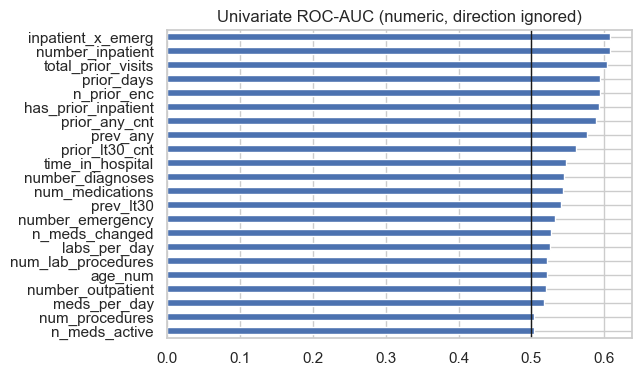

In [16]:
from sklearn.metrics import roc_auc_score
from sklearn.feature_selection import mutual_info_classif

X = prepare_features(df)
y = df.target

# (a) univariate ROC-AUC of every numeric feature
auc = {c: roc_auc_score(y, X[c]) for c in NUM_COLS}
auc = pd.Series(auc)
(auc - 0.5).abs().add(0.5).sort_values().plot.barh(figsize=(6, 4), title="Univariate ROC-AUC (numeric, direction ignored)")
plt.axvline(0.5, color="k", lw=1); plt.show()

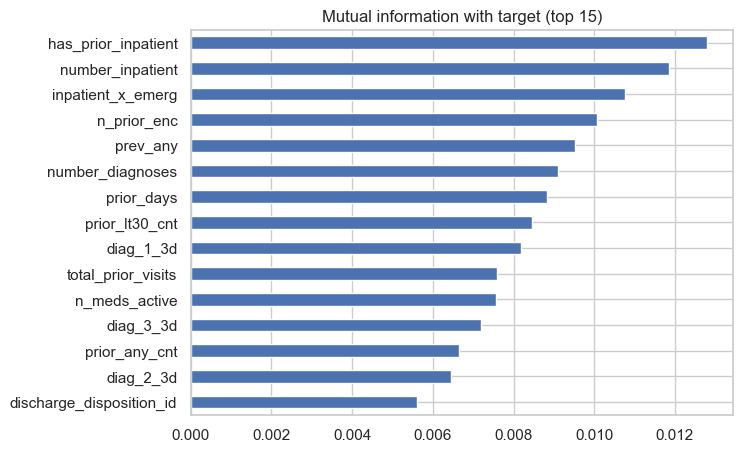

In [17]:
# (b) mutual information for all features (categoricals ordinal-encoded)
Xo = X.copy()
for c in CAT_COLS:
    Xo[c] = Xo[c].astype("category").cat.codes
mi = mutual_info_classif(Xo, y, discrete_features=[c in CAT_COLS for c in Xo.columns], random_state=1)
mi = pd.Series(mi, index=Xo.columns).sort_values(ascending=False)
mi.head(15).sort_values().plot.barh(figsize=(7, 5), title="Mutual information with target (top 15)")
plt.show()

**Takeaways**

* Dataset is **imbalanced** (~11% positives) -> accuracy is misleading; we use **ROC-AUC** (main) and **PR-AUC**.
* Most informative features: prior inpatient / emergency visits (`number_inpatient`, `total_prior_visits`), discharge disposition, number of diagnoses, time in hospital, number of medications, age.
* The signal is weak overall (this is a hard, noisy problem; published models reach ROC-AUC ~0.65-0.70), so we should not expect big numbers.
* Dropped: `weight`, `encounter_id`, `examide`, `citoglipton`, and the raw `readmitted`/`diag_*` columns (replaced by `target` and diagnosis groups). Final feature engineering (diagnosis groups and 3-digit codes, ratio features, patient-history features) is implemented in `features.py`.

## 7. Modelling

**Split:** 60% train / 20% validation / 20% test, grouped by `patient_nbr` so a patient never appears in more than one split.
Hyper-parameters are tuned on the validation set; the test set is only used once at the end.

In [18]:
from sklearn.model_selection import GroupShuffleSplit, ParameterSampler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from xgboost import XGBClassifier
import time

groups = df.patient_nbr
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=1)
trainval_idx, test_idx = next(gss.split(X, y, groups))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=1)   # 0.25 * 0.8 = 0.2
tr_rel, va_rel = next(gss2.split(X.iloc[trainval_idx], y.iloc[trainval_idx], groups.iloc[trainval_idx]))
train_idx, val_idx = trainval_idx[tr_rel], trainval_idx[va_rel]

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
print(len(X_train), len(X_val), len(X_test))
print(y_train.mean().round(4), y_val.mean().round(4), y_test.mean().round(4))

59595 19897 19851
0.1137 0.1145 0.1137


In [19]:
def make_pre():
    return ColumnTransformer([
        ("num", StandardScaler(), NUM_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CAT_COLS),
    ])

def evaluate(model, name=None):
    t = time.time()
    pipe = Pipeline([("pre", make_pre()), ("clf", model)]).fit(X_train, y_train)
    p = pipe.predict_proba(X_val)[:, 1]
    res = dict(model=name, val_roc_auc=roc_auc_score(y_val, p), val_pr_auc=average_precision_score(y_val, p), sec=time.time() - t)
    return pipe, res

results = []
_, r = evaluate(DummyClassifier(strategy="prior"), "baseline (prior)"); results.append(r)
_, r = evaluate(LogisticRegression(max_iter=1000), "logreg C=1"); results.append(r)
pd.DataFrame(results)

,model,val_roc_auc,val_pr_auc,sec
0,baseline (prior),0.500000,0.114490,2.957512
1,logreg C=1,0.670003,0.228351,4.978450


### Logistic regression tuning (C, class weights)

In [20]:
lr_res = []
for C_ in [0.001, 0.01, 0.1, 1]:
    for cw in [None, "balanced"]:
        _, r = evaluate(LogisticRegression(C=C_, class_weight=cw, max_iter=2000), f"logreg C={C_} cw={cw}")
        r.update(C=C_, class_weight=cw); lr_res.append(r)
lr_df = pd.DataFrame(lr_res).sort_values("val_roc_auc", ascending=False)
lr_df

,model,val_roc_auc,val_pr_auc,sec,C,class_weight
4,logreg C=0.1 cw=None,0.676566,0.228178,4.087779,0.100,None
3,logreg C=0.01 cw=balanced,0.676068,0.219783,3.639647,0.010,balanced
2,logreg C=0.01 cw=None,0.673668,0.219382,3.938265,0.010,None
5,logreg C=0.1 cw=balanced,0.673656,0.225488,4.531701,0.100,balanced
6,logreg C=1 cw=None,0.670003,0.228351,5.054083,1.000,None
1,logreg C=0.001 cw=balanced,0.669061,0.213346,3.436584,0.001,balanced
7,logreg C=1 cw=balanced,0.668051,0.225732,5.755729,1.000,balanced
0,logreg C=0.001 cw=None,0.664431,0.211226,3.381458,0.001,None


### Random forest tuning

In [21]:
rf_space = dict(n_estimators=[200, 300], max_depth=[8, 12, 16, 24], min_samples_leaf=[5, 10, 20, 50],
                max_features=["sqrt", 0.3], class_weight=[None, "balanced_subsample"])
rf_res = []
for i, p in enumerate(ParameterSampler(rf_space, n_iter=10, random_state=1)):
    _, r = evaluate(RandomForestClassifier(**p, n_jobs=-1, random_state=1), f"rf {i}")
    r.update(p); rf_res.append(r)
rf_df = pd.DataFrame(rf_res).sort_values("val_roc_auc", ascending=False)
rf_df

,model,val_roc_auc,val_pr_auc,sec,n_estimators,min_samples_leaf,max_features,max_depth,class_weight
9,rf 9,0.681763,0.233489,16.066656,300,10,sqrt,24,None
8,rf 8,0.679245,0.234831,28.654928,300,50,0.3,12,None
4,rf 4,0.679149,0.231999,10.495644,300,5,sqrt,16,None
6,rf 6,0.679079,0.239998,59.339645,200,10,0.3,24,balanced_subsample
7,rf 7,0.678707,0.229032,10.242919,300,10,sqrt,16,None
3,rf 3,0.678569,0.241311,51.376204,200,5,0.3,24,None
0,rf 0,0.677016,0.237650,96.494829,300,5,0.3,24,balanced_subsample
2,rf 2,0.675011,0.221422,10.986681,300,50,sqrt,24,None
1,rf 1,0.673368,0.230618,42.410413,200,5,0.3,16,balanced_subsample
5,rf 5,0.672290,0.216944,9.202054,200,50,sqrt,24,balanced_subsample


### XGBoost tuning

In [22]:
xgb_space = dict(n_estimators=[300, 600, 900], learning_rate=[0.01, 0.02, 0.03, 0.05], max_depth=[3, 4, 5, 6],
                 min_child_weight=[1, 5, 10, 20], subsample=[0.6, 0.7, 0.85], colsample_bytree=[0.3, 0.5, 0.7],
                 reg_lambda=[1, 5, 10], scale_pos_weight=[1, 3])
xgb_res = []
for i, p in enumerate(ParameterSampler(xgb_space, n_iter=25, random_state=2)):
    _, r = evaluate(XGBClassifier(**p, tree_method="hist", n_jobs=-1, random_state=1), f"xgb {i}")
    r.update(p); xgb_res.append(r)
xgb_df = pd.DataFrame(xgb_res).sort_values("val_roc_auc", ascending=False)
xgb_df

,model,val_roc_auc,val_pr_auc,sec,subsample,scale_pos_weight,reg_lambda,n_estimators,min_child_weight,max_depth,learning_rate,colsample_bytree
7,xgb 7,0.687852,0.245711,4.371677,0.70,1,1,300,5,6,0.05,0.5
19,xgb 19,0.686563,0.247305,7.267889,0.70,1,5,900,1,6,0.01,0.5
24,xgb 24,0.686035,0.241668,6.923013,0.60,3,1,900,10,5,0.01,0.7
11,xgb 11,0.685356,0.246256,4.269917,0.85,1,10,300,5,5,0.05,0.5
22,xgb 22,0.684588,0.247643,5.975051,0.85,1,1,600,1,6,0.02,0.5
5,xgb 5,0.684588,0.244517,5.430125,0.60,1,1,600,1,5,0.02,0.5
18,xgb 18,0.684001,0.240085,4.516788,0.60,1,10,300,5,6,0.02,0.5
0,xgb 0,0.683755,0.241046,6.575433,0.70,3,5,900,20,4,0.01,0.7
4,xgb 4,0.683539,0.240400,5.127234,0.70,1,1,600,1,4,0.02,0.3
3,xgb 3,0.683400,0.241281,5.854615,0.60,1,10,600,10,6,0.03,0.3


### Model comparison (validation set)

In [23]:
best = pd.DataFrame([
    results[0], lr_df.iloc[0].to_dict(), rf_df.iloc[0].to_dict(), xgb_df.iloc[0].to_dict(),
])[["model", "val_roc_auc", "val_pr_auc", "sec"]]
best["model"] = ["baseline", "logistic regression", "random forest", "xgboost"]
best.round(4)

,model,val_roc_auc,val_pr_auc,sec
0,baseline,0.5000,0.1145,2.9575
1,logistic regression,0.6766,0.2282,4.0878
2,random forest,0.6818,0.2335,16.0667
3,xgboost,0.6879,0.2457,4.3717


In [24]:
best_params = xgb_df.iloc[0][["n_estimators", "learning_rate", "max_depth", "min_child_weight", "subsample", "colsample_bytree", "reg_lambda", "scale_pos_weight"]].to_dict()
print(best_params)

{'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 6, 'min_child_weight': 5, 'subsample': 0.7, 'colsample_bytree': 0.5, 'reg_lambda': 1, 'scale_pos_weight': 1}


## 8. Final model: refit on train + validation, evaluate once on test

In [25]:
def pick(df_, keys):
    row = df_.iloc[0]
    out = {}
    for k in keys:
        v = row[k]
        if isinstance(v, (np.integer,)): v = int(v)
        elif isinstance(v, (np.floating,)): v = float(v)
        out[k] = v
    return out

cands = {
    "logistic regression": (lr_df.iloc[0].val_roc_auc, lambda: LogisticRegression(**pick(lr_df, ["C", "class_weight"]), max_iter=2000)),
    "random forest": (rf_df.iloc[0].val_roc_auc, lambda: RandomForestClassifier(**pick(rf_df, list(rf_space)), n_jobs=-1, random_state=1)),
    "xgboost": (xgb_df.iloc[0].val_roc_auc, lambda: XGBClassifier(**pick(xgb_df, list(xgb_space)), tree_method="hist", n_jobs=-1, random_state=1, eval_metric="logloss")),
}
winner = max(cands, key=lambda k: cands[k][0])
print("best on validation:", winner)

X_tv, y_tv = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
test_scores = {}
fitted = {}
for name, (_, mk) in cands.items():
    pipe = Pipeline([("pre", make_pre()), ("clf", mk())]).fit(X_tv, y_tv)
    p = pipe.predict_proba(X_test)[:, 1]
    fitted[name] = (pipe, p)
    test_scores[name] = dict(test_roc_auc=roc_auc_score(y_test, p), test_pr_auc=average_precision_score(y_test, p))
pd.DataFrame(test_scores).T.round(4)

best on validation: xgboost


,test_roc_auc,test_pr_auc
logistic regression,0.6789,0.2325
random forest,0.6852,0.2342
xgboost,0.6912,0.2534


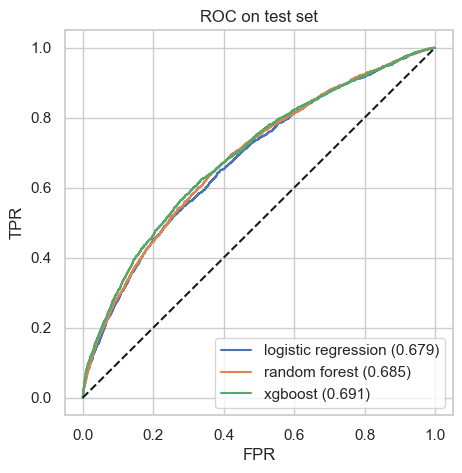

In [26]:
plt.figure(figsize=(5, 5))
for name, (_, p) in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, p); plt.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(); plt.title("ROC on test set"); plt.show()

### How would it be used? Flag the highest-risk patients
Care teams have limited capacity, so we flag the top-k% highest-risk discharges and check how many true readmissions are caught.

In [27]:
pipe, p = fitted[winner]
order = np.argsort(-p)
yt = y_test.values[order]
rows = []
for k in [0.05, 0.1, 0.2, 0.3]:
    n = int(len(yt) * k)
    rows.append(dict(flagged=f"top {int(k*100)}%", precision=yt[:n].mean(), recall=yt[:n].sum() / yt.sum(), lift=yt[:n].mean() / yt.mean()))
pd.DataFrame(rows).round(3)

,flagged,precision,recall,lift
0,top 5%,0.356,0.156,3.128
1,top 10%,0.295,0.260,2.595
2,top 20%,0.244,0.429,2.144
3,top 30%,0.209,0.551,1.837


### Feature importance of the final model

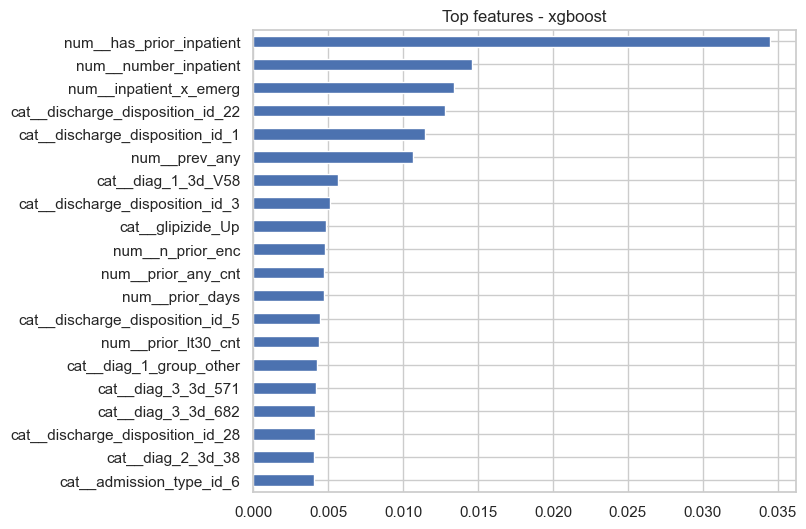

In [28]:
if winner == "xgboost":
    names = pipe.named_steps["pre"].get_feature_names_out()
    imp = pd.Series(pipe.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
elif winner == "random forest":
    names = pipe.named_steps["pre"].get_feature_names_out()
    imp = pd.Series(pipe.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
else:
    names = pipe.named_steps["pre"].get_feature_names_out()
    imp = pd.Series(np.abs(pipe.named_steps["clf"].coef_[0]), index=names).sort_values(ascending=False)
imp.head(20).sort_values().plot.barh(figsize=(7, 6), title=f"Top features - {winner}")
plt.show()

## Conclusions
* Best model on validation is printed above; the final numbers on the held-out test set are in the table.
* ROC-AUC around 0.65-0.70 is in line with published results for this dataset: readmission is intrinsically hard to predict from administrative data.
* The model is useful for **risk-ranking** (lift in the top 10-20% of patients) rather than as a yes/no oracle.
* The winning configuration is used in `train.py` to train and save the final model.